In [2]:
import pandas as pd
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
print(df.dtypes)
print(df["Churn"].value_counts())

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [4]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64
Duplicates: 0


In [5]:
from sklearn.model_selection import train_test_split

df = df.drop(columns=["customerID"])
y = df["Churn"].map({"No": 0, "Yes": 1})
X = df.drop(columns=["Churn"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

(5634, 19) (1409, 19)
0.2653532126375577 0.2654364797728886


In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_cols = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]
cat_cols = [c for c in X.columns if c not in num_cols]

num_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler())])

cat_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))])

preprocess = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols)], sparse_threshold=0)

print("Number columns:", num_cols)
print("Text columns:", len(cat_cols))

Number columns: ['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen']
Text columns: 15


In [15]:


from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score,
                             recall_score, f1_score, matthews_corrcoef)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "kNN": KNeighborsClassifier(n_neighbors=15),
    "Naive Bayes": GaussianNB(),
    "Random Forest (Ensemble)": RandomForestClassifier(n_estimators=200, random_state=42)}

results = []
for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    prob = pipe.predict_proba(X_test)[:, 1]
    results.append([name,
        accuracy_score(y_test, pred), roc_auc_score(y_test, prob),
        precision_score(y_test, pred), recall_score(y_test, pred),
        f1_score(y_test, pred), matthews_corrcoef(y_test, pred)])

res = pd.DataFrame(results, columns=["Model","Accuracy","AUC","Precision","Recall","F1","MCC"])
res.round(3)

,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.806,0.842,0.657,0.559,0.604,0.479
1,Decision Tree,0.798,0.830,0.635,0.567,0.599,0.466
2,kNN,0.777,0.821,0.583,0.561,0.572,0.422
3,Naive Bayes,0.695,0.807,0.459,0.837,0.593,0.424
4,Random Forest (Ensemble),0.784,0.819,0.619,0.481,0.541,0.408


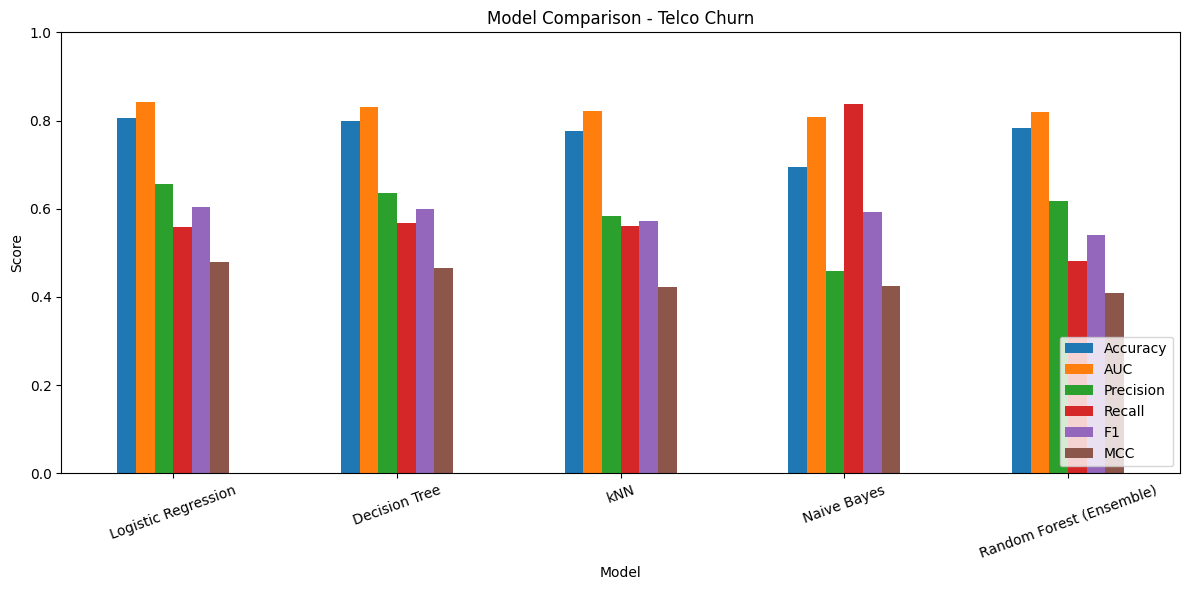

In [17]:
import matplotlib.pyplot as plt

res.set_index("Model").plot(kind="bar", figsize=(12, 6))
plt.title("Model Comparison - Telco Churn")
plt.ylabel("Score")
plt.xticks(rotation=20)
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("model_comparison.png")
plt.show()

In [19]:
import joblib, os

test_df = X_test.copy()
test_df["Churn"] = y_test
test_df.to_csv("test_data.csv", index=False)

os.makedirs("model", exist_ok=True)
for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    pipe.fit(X_train, y_train)
    joblib.dump(pipe, f"model/{name.split()[0].lower()}.pkl")

print(os.listdir("model"))

['naive.pkl', 'knn.pkl', 'random.pkl', 'decision.pkl', 'logistic.pkl']


In [21]:
with open("requirements.txt", "w") as f:
    f.write("scikit-learn\nnumpy\npandas\nmatplotlib\nseaborn\njoblib\n")
print("done")

done
